# Estatísticas do XGBoost — F1, Recall e Precision

**F1 seleciona os parâmetros e o threshold**, buscando equilíbrio entre Precision
e Recall. **AUPRC/AP é diagnóstico**, sem decidir a configuração atual.
Não existe garantia de maximizar simultaneamente as três métricas; o desempate
usa Precision e Recall. A classe positiva é fraude (Class=1).

A CV de parâmetros usa uma referência comum de decisão em 0,50 para comparar as
receitas. Esse não é o limiar operacional imposto: depois, GridSearchCV escolhe
o threshold por F1 numa janela TRAIN reservada, antes da validação posterior.
O mesmo pipeline congelado é aplicado a essa validação, sem refit após escolher o limiar.

Este notebook apenas lê relatórios, sem fit ou predição. Treino em
[xgboost_gridsearch.ipynb](xgboost_gridsearch.ipynb), configuração em
`configs/xgboost_f1_threshold.yaml`. O TEST não foi reavaliado e o RF escolhido
permanece preservado. O histórico já explorou esses dados: não é confirmação independente.

In [1]:
# Somente leitura de artefatos agregados: nenhuma célula ajusta ou executa modelos.
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
from fraud_detection.reporting import readable_table

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
if not (ROOT / "pyproject.toml").exists():
    raise RuntimeError("Abra pela raiz do projeto ou pela pasta notebooks.")
PREFIX = "xgboost_f1_threshold"
METRICS, FIGURES = ROOT / "reports/metrics", ROOT / "reports/figures"
EXPERIMENTS = ROOT / "reports/experiments"

def read_json(path):
    if not path.is_file():
        raise FileNotFoundError("Relatório ausente. Execute a busca usando configs/xgboost_f1_threshold.yaml.")
    return json.loads(path.read_text(encoding="utf-8"))

def table(name):
    return pd.read_csv(METRICS / f"{PREFIX}_{name}.csv")

def figure(name, width=1100):
    display(Image(filename=str(FIGURES / f"{PREFIX}_{name}.png"), width=width))

def show(frame):
    display(readable_table(frame))

manifest = read_json(EXPERIMENTS / f"{PREFIX}_manifest.json")
result = read_json(METRICS / f"{PREFIX}_model_metrics.json")
assert not manifest["test_evaluated"]
assert not manifest["validation_used_for_selection"]
assert not manifest["selected_random_forest_replaced"]
assert "learning_rate" in manifest["best_params"]

## 1. Modelo, configuração e origem dos resultados

Uma linha é uma transação no momento da autorização; Class=1 é fraude e Class=0,
legítima. Os dados são numéricos, com Time, Amount e V1–V28 (PCA anônimo).
O pipeline é seleção de features → imputação → StandardScaler → SMOTE → XGBoost.

As etapas aprendem apenas no treino de cada fold. A regra de retirada exige
simultaneamente `|Pearson| < 0,090 E importância por permutação < 0,100`; a importância
para selecionar features usa uma janela interna ao próprio fit. SMOTE cria minoria
até a razão fraude/legítima 0,1, sem undersampling e sem reamostrar a validação.

O prefixo do TRAIN recebe a busca e o refit da melhor combinação. A última janela
do TRAIN fica fora da busca atual e só é prevista após congelar os parâmetros.
O artefato é experimental e não foi reajustado em todo o TRAIN.

Nesta rodada, o modelo é ajustado no prefixo de **119.920 transações**. As
**36.213 transações seguintes** escolhem o threshold; as **54.159 posteriores**
ficam para validação. Os dois folds da seleção por AP terminam antes da janela
de threshold. O pipeline usado para escolher o limiar permanece congelado até
avaliar a validação seguinte: não há refit que altere os scores após escolher o limiar.

In [2]:
display({
    "Melhores parâmetros na grade": manifest["best_params"],
    "Threshold escolhido por F1": manifest["threshold"],
    "F1 médio na CV anterior ao threshold": manifest["best_cv_score"],
    "AP da CV (diagnóstico)": manifest["best_cv_ap"],
    "TRAIN total (transações)": manifest["train_rows"],
    "Prefixo de busca/refit (transações)": manifest["search_fit_rows"],
    "Validação separada (transações)": manifest["validation_rows"],
    "Fraudes na validação separada": manifest["validation_frauds"],
    "Último Time do prefixo": manifest["search_fit_time_max"],
    "Janela threshold (transações)": manifest["threshold_rows"],
    "Fraudes na janela threshold": manifest["threshold_frauds"],
    "Primeiro Time da janela threshold": manifest["threshold_time_min"],
    "Último Time da janela threshold": manifest["threshold_time_max"],
    "Primeiro Time da validação separada": manifest["validation_time_min"],
    "Último Time da validação separada": manifest["validation_time_max"],
    "Features mantidas": manifest["selected_features"],
    "Dataset SHA-256": manifest["dataset_sha256"],
    "Artefato SHA-256": manifest["artifact_sha256"],
    "Versões": manifest["versions"],
})
show(pd.read_csv(EXPERIMENTS / f"{PREFIX}_folds.csv"))

{'Melhores parâmetros na grade': {'learning_rate': 0.01,
  'max_depth': 4,
  'n_estimators': 200,
  'reg_alpha': 0.0,
  'reg_lambda': 1.0},
 'Threshold escolhido por F1': 0.6,
 'F1 médio na CV anterior ao threshold': 0.8245342575973262,
 'AP da CV (diagnóstico)': 0.7602355102059624,
 'TRAIN total (transações)': 210292,
 'Prefixo de busca/refit (transações)': 119920,
 'Validação separada (transações)': 54159,
 'Fraudes na validação separada': 44,
 'Último Time do prefixo': 75810.0,
 'Janela threshold (transações)': 36213,
 'Fraudes na janela threshold': 90,
 'Primeiro Time da janela threshold': 75811.0,
 'Último Time da janela threshold': 108793.0,
 'Primeiro Time da validação separada': 108799.0,
 'Último Time da validação separada': 138230.0,
 'Features mantidas': ['V1',
  'V2',
  'V3',
  'V4',
  'V5',
  'V7',
  'V9',
  'V10',
  'V11',
  'V12',
  'V14',
  'V16',
  'V17',
  'V18'],
 'Dataset SHA-256': '76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89',
 'Artefato SHA-25

,Fold temporal,Transações de treino,Transações de validação,Fraudes no treino,Fraudes na validação,Último Time do treino,Primeiro Time da validação,Último Time da validação
0,1,30.598,44.312,101,82,"36.054,0000","36.055,0000","55.952,0000"
1,2,74.910,45.010,183,59,"55.952,0000","55.953,0000","75.810,0000"


## 2. Grade e critério de seleção

A grade pesquisa os mesmos 162 candidatos em learning_rate, max_depth,
n_estimators, reg_alpha e reg_lambda. Os mesmos dois folds anteriores à janela
do threshold são usados. Scores por fold são reutilizados somente após verificar
dados, versões, configurações e fronteiras.

A seleção agora usa **F1 médio**, com Precision e Recall para desempatar. AP e
ROC-AUC continuam registrados. Na CV dos parâmetros, as predições usam a referência
comum 0,50; depois, o limiar operacional é escolhido na grade interna por F1.
É uma busca em duas etapas, não uma grade conjunta exaustiva de parâmetros e limiar.
A validação posterior fica fora das duas escolhas da rodada.

In [3]:
display({
    "Grade": manifest["settings"]["param_grid"],
    "Combinações totais": manifest["combinations"],
    "Folds por combinação": manifest["inner_folds"],
    "Fits equivalentes da grade completa": manifest["grid_fits"],
    "Fits novos": manifest["executed_grid_fits"],
    "Fits reutilizados": manifest["reused_grid_fits"],
    "Proveniência da reutilização": manifest["reuse"],
    "Tempo da rodada completa (minutos)": round(manifest["cv_seconds"] / 60, 2),
})

{'Grade': {'max_depth': [3, 4, 6],
  'n_estimators': [100, 200, 400],
  'reg_alpha': [0.0, 1.0],
  'reg_lambda': [0.0, 1.0, 5.0],
  'learning_rate': [0.01, 0.05, 0.1]},
 'Combinações totais': 162,
 'Folds por combinação': 2,
 'Fits equivalentes da grade completa': 324,
 'Fits novos': 0,
 'Fits reutilizados': 324,
 'Proveniência da reutilização': {'manifest_sha256': '4731d085bda0beac3d2386a319e8e05b6cf1e386097c7b30e09af10cc18ba091',
  'cv_scores_sha256': 'ea023c5a685196dadf4a2c26fae6cc3dddeecf02a2edf2265f3d501d396012a5',
  'origin_prefix': 'xgboost_learning_rate',
  'candidates': 162},
 'Tempo da rodada completa (minutos)': 0.67}

## 3. F1, Recall e Precision do XGBoost otimizado — validação separada

As três barras representam o mesmo XGBoost na última validação temporal do TRAIN,
fora da busca atual, com threshold selecionado na janela interna e distribuição original. Os rótulos estão
em porcentagem. Não são médias de CV nem resultados de TEST.

- **Recall:** TP/(TP+FN), fração das fraudes reais que foi detectada.
- **Precision:** TP/(TP+FP), fração dos alertas que correspondia a fraude real.
- **F1:** 2PR/(P+R), média harmônica de Precision e Recall com pesos iguais.

O resultado deve ser lido junto às contagens: a janela tem poucas fraudes e já
participou das análises históricas do projeto. A busca atual não usou essa janela
para escolher os parâmetros, mas ela não é confirmação independente de toda a história.

,Receita,Origem,Limiar de alerta,F1 (%),Recall (%),Precision (%),AP (score),TP: fraudes detectadas,FP: falsos alertas,FN: fraudes não detectadas,TN: legítimas liberadas
0,XGBoost f1 + SMOTE,Validação temporal TRAIN posterior ao ajuste do threshold; histórico explorado,"0,6000",68.00%,77.27%,60.71%,"0,6958",34,22,10,54.093


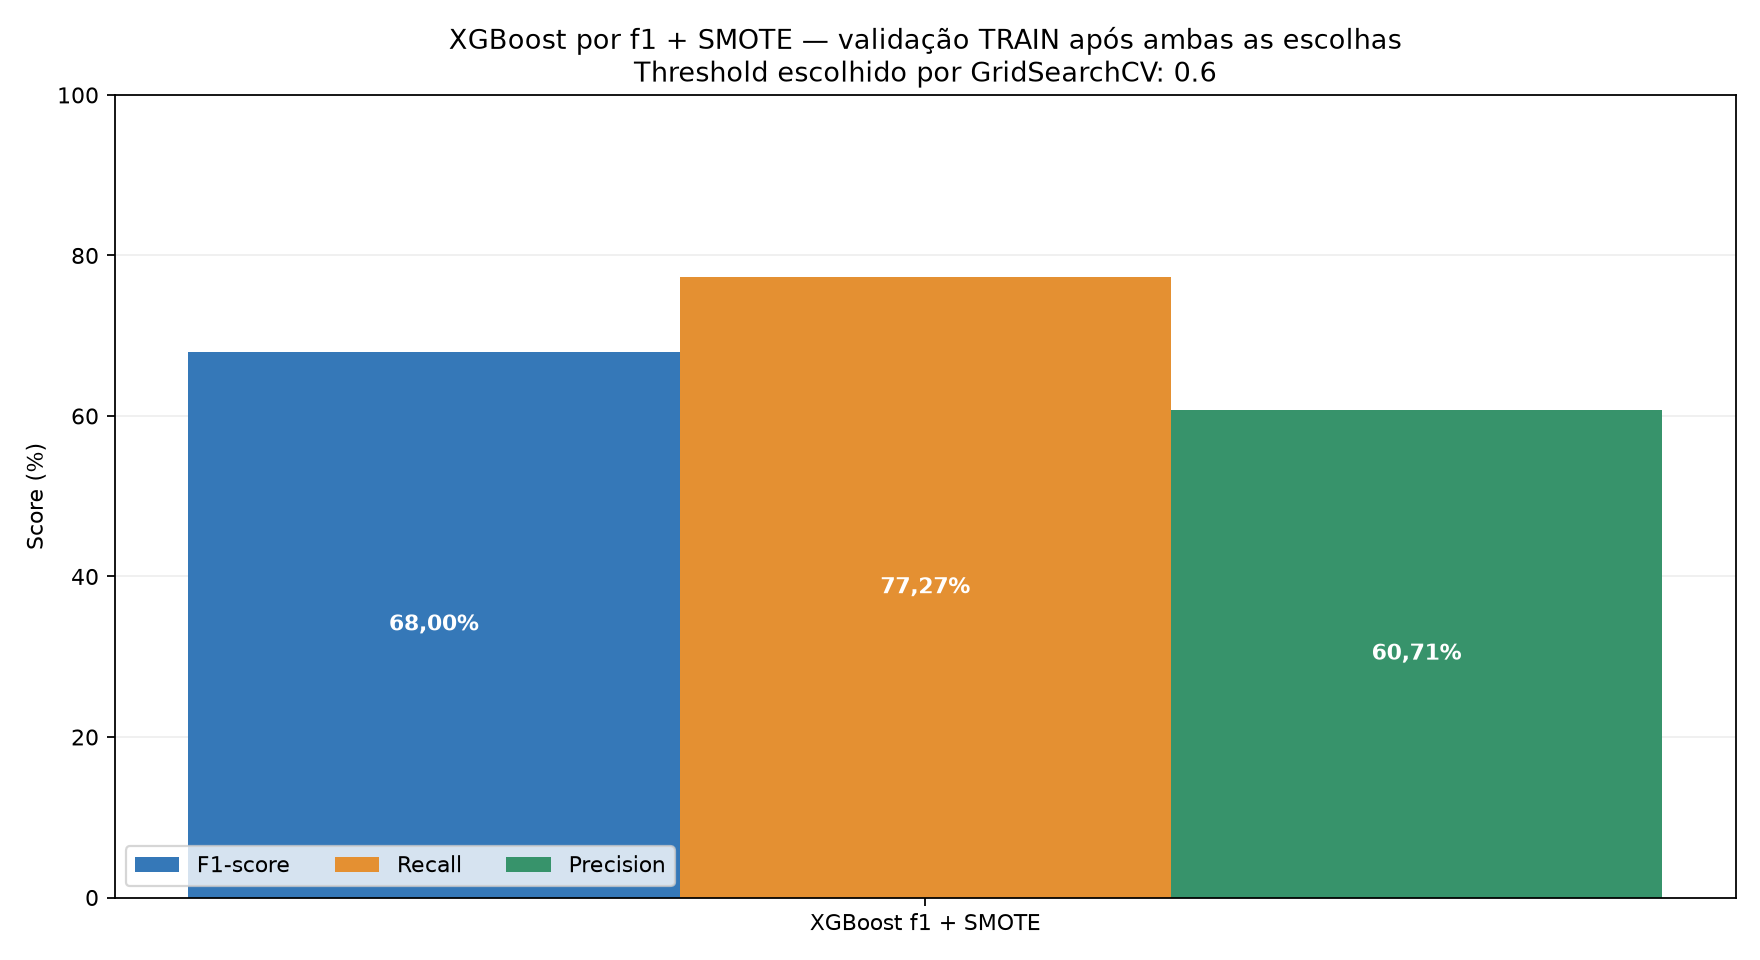

O modelo detectou **34 das 44 fraudes**, deixou **10 sem alerta** e gerou **22 falsos alertas**.

In [4]:
show(table("model_metrics")[["model", "source", "threshold", "f1", "recall", "precision",
                             "average_precision", "tp", "fp", "fn", "tn"]])
figure("model_f1_recall_precision", 1000)
display(Markdown(
    f"O modelo detectou **{int(result['tp'])} das {int(result['positives'])} fraudes**, "
    f"deixou **{int(result['fn'])} sem alerta** e gerou **{int(result['fp'])} falsos alertas**."
))

## 4. Matriz de confusão: contagens e proporções por classe

**TN:** legítimas corretamente liberadas. **FP:** legítimas alertadas.
**FN:** fraudes que ficaram sem alerta. **TP:** fraudes detectadas.

Na matriz normalizada, cada linha soma 100%. Para fraudes, as células indicam
Recall e taxa de fraudes perdidas; para legítimas, especificidade e FPR.
Como as classes têm tamanhos muito diferentes, examine simultaneamente contagens
e percentuais. Uma baixa FPR não significa necessariamente poucos falsos alertas.

,TN: legítimas liberadas,FP: falsos alertas,FN: fraudes não detectadas,TP: fraudes detectadas
0,54.093,22,10,34


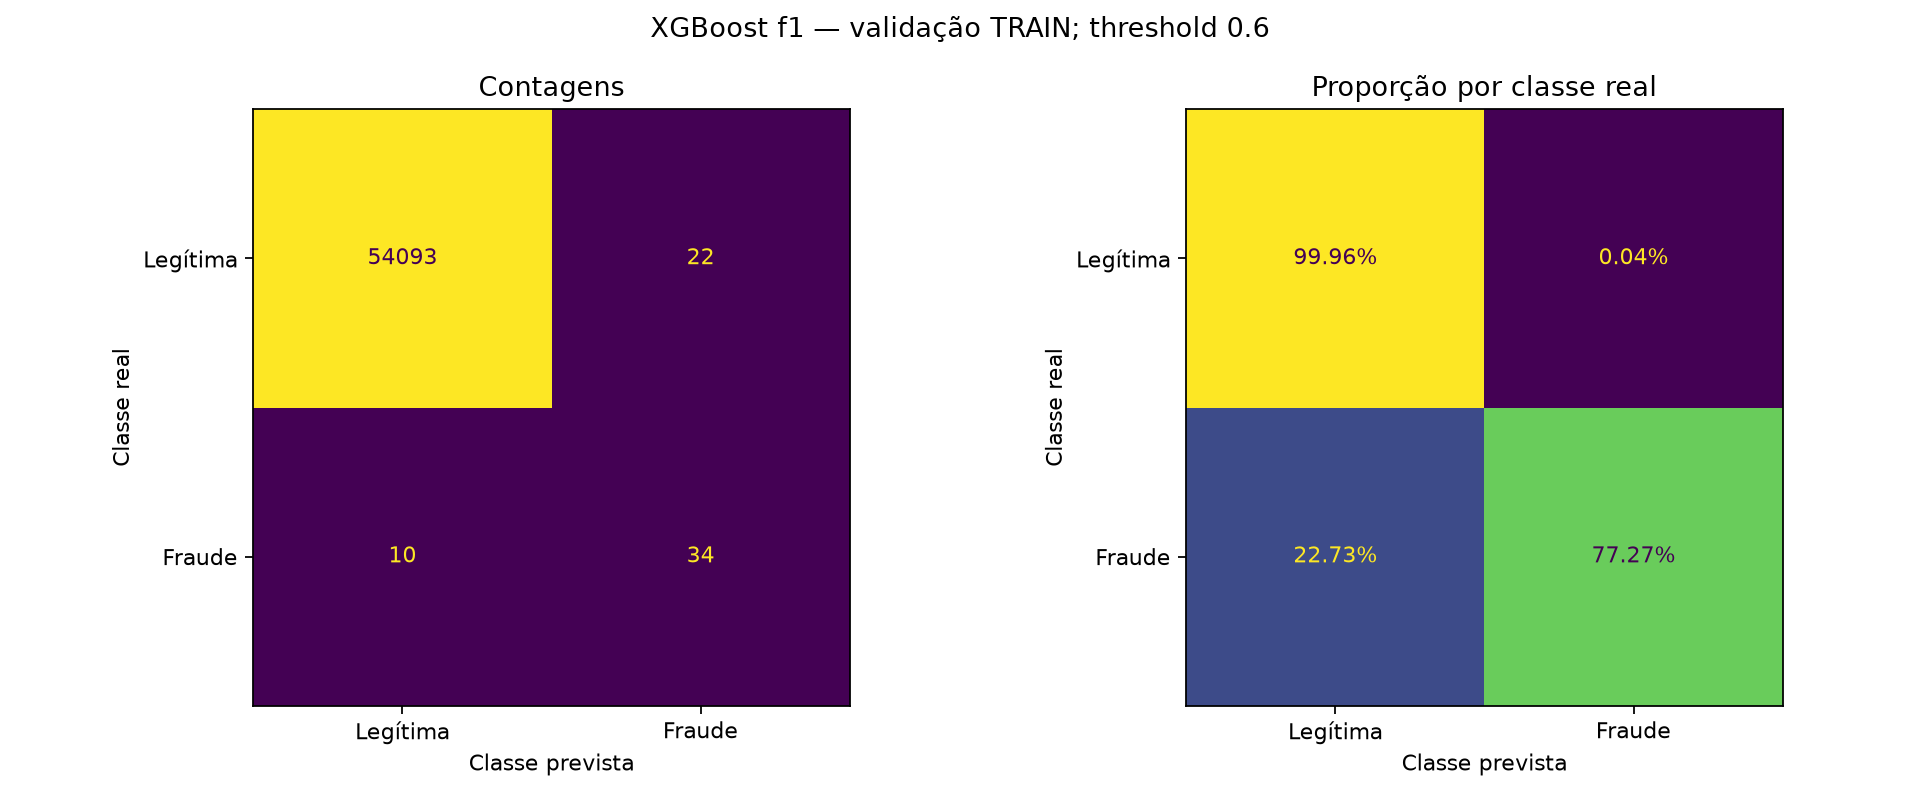

In [5]:
show(pd.DataFrame([{key: result[key] for key in ["tn", "fp", "fn", "tp"]}]))
figure("confusion")

## 5. Todas as métricas, unidades e denominadores

A tabela traz as fórmulas e a direção desejável. Acurácia pode parecer alta pela
predominância de legítimas; Balanced Accuracy dá o mesmo peso às duas classes.

FPR divide FP pelas legítimas reais; FDR divide FP por alertas. FNR divide FN
pelas fraudes reais; fraudes entre liberadas divide FN pelo total liberado.
São denominadores e perguntas diferentes. Denominador zero é não definido.
Métricas com unidade `%` já estão na escala 0–100 na tabela abaixo.

AP e ROC-AUC medem ordenação; Log Loss e Brier medem erros probabilísticos (menor
é melhor). MCC e Kappa medem concordância entre decisões e rótulos; não são taxas
de acerto. F2/F3 não orientam esta rodada.

In [6]:
definitions = table("metric_definitions")
percentage = definitions.loc[definitions.unit.eq("%")].rename(columns={
    "name": "Métrica", "value": "Valor (%)", "definition": "Significado / denominador",
    "preferred": "Direção desejável",
})
display(percentage[["Métrica", "Valor (%)", "Significado / denominador", "Direção desejável"]]
        .style.format({"Valor (%)": "{:.4f}%"}))
scores = definitions.loc[~definitions.unit.eq("%")].rename(columns={
    "name": "Métrica", "value": "Valor", "unit": "Unidade", "definition": "Significado",
    "preferred": "Direção desejável",
})
display(scores[["Métrica", "Valor", "Unidade", "Significado", "Direção desejável"]]
        .style.format({"Valor": "{:.6f}"}))

,Métrica,Valor (%),Significado / denominador,Direção desejável
0,Precision,60.7143%,TP/(TP+FP): fração dos alertas que era fraude,Maior
1,Recall / sensibilidade,77.2727%,TP/(TP+FN): fração das fraudes detectada,Maior
2,F1,68.0000%,2PR/(P+R): média harmônica simétrica de Precision e Recall,Maior
3,Especificidade,99.9593%,TN/(TN+FP): legítimas corretamente liberadas,Maior
4,Acurácia,99.9409%,(TP+TN)/n: acertos totais; pode enganar em classe rara,Maior
5,Balanced Accuracy,88.6160%,(Recall+Especificidade)/2,Maior
6,Valor preditivo negativo,99.9815%,TN/(TN+FN): legítimas entre não alertadas,Maior
7,Taxa de falsos positivos (FPR),0.0407%,FP/(FP+TN): legítimas alertadas,Menor
8,Taxa de falsos negativos (FNR),22.7273%,FN/(FN+TP): fraudes não detectadas,Menor
9,Parcela de alertas falsos (FDR),39.2857%,FP/(FP+TP): alertas que eram legítimos,Menor


,Métrica,Valor,Unidade,Significado,Direção desejável
13,Average Precision (AP),0.695773,score 0–1,Resumo de Precision ponderado pelos ganhos de Recall; usa scores,Maior
14,Área trapezoidal PR,0.690345,score 0–1,Integral trapezoidal da curva Precision–Recall; difere de AP,Maior
15,ROC-AUC,0.968282,score 0–1,Ordenação fraude vs. legítima; complemento à AP,Maior
16,Log Loss,0.030286,perda,Perda probabilística; penaliza erros confiantes,Menor
17,Brier score,0.002130,erro quadrático,Média de (probabilidade−rótulo)²,Menor
18,Coeficiente de Matthews (MCC),0.684665,score −1–1,Associação entre decisões e rótulos usando TN/FP/FN/TP,Maior
19,Kappa de Cohen,0.679709,score −1–1,Concordância corrigida pela concordância esperada ao acaso,Maior


## 6. Precision–Recall / AUPRC e ROC

AP (Average Precision) resume a curva PR ponderando a precisão pelos ganhos de
Recall. A área trapezoidal PR usa outra integração e pode diferir de AP.
A linha de prevalência é a referência ingênua e o ponto vermelho marca threshold selecionado na janela interna.
AP e ROC-AUC não mudam quando se altera apenas o threshold sobre os mesmos scores.

ROC-AUC complementa a análise de uma classe rara, mas não substitui PR/AP,
Precision, Recall e contagens. Um aumento de F1 num limiar não garante aumento de AP.

,AP (score),pr_auc_trapezoid,ROC-AUC (score),prevalence
0,"0,6958","0,6903","0,9683","0,0008"


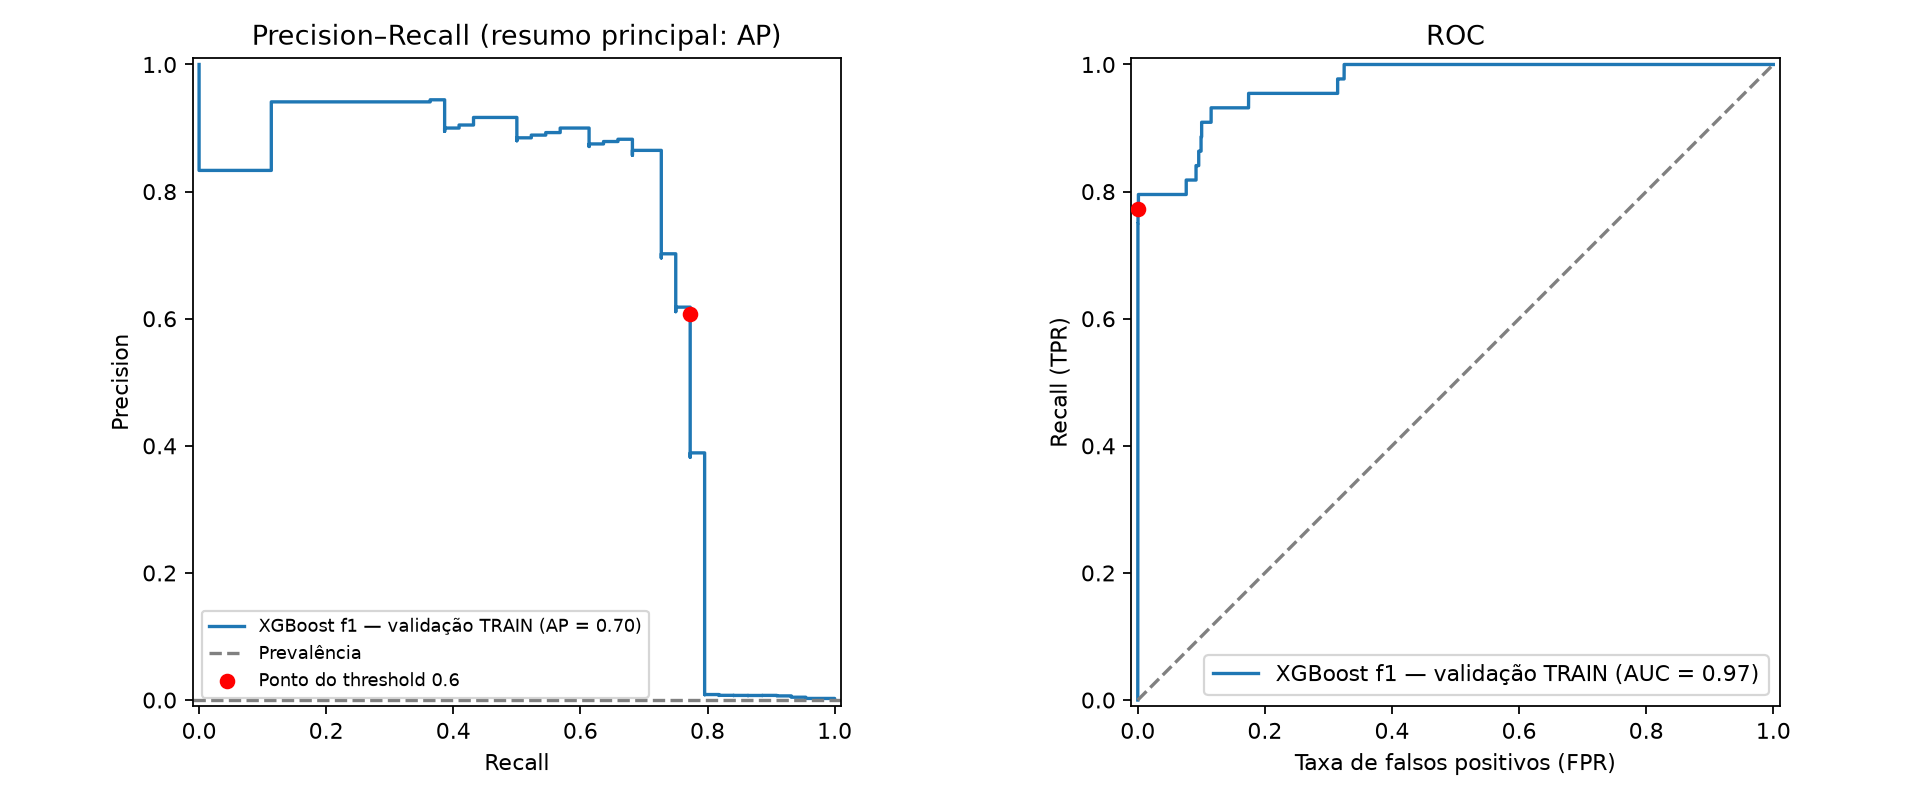

In [7]:
show(pd.DataFrame([{key: result[key] for key in
    ["average_precision", "pr_auc_trapezoid", "roc_auc", "prevalence"]}]))
figure("pr_roc")

## 7. Relatório por classe, média macro e ponderada

Na linha Fraude (1) estão as métricas principais. Para Legítima (0), o cálculo
trata a classe 0 como positiva: seu Recall equivale à especificidade e sua Precision
ao valor preditivo negativo do problema de fraude.

Suporte é a quantidade de transações reais. Média macro dá peso igual às classes;
média ponderada usa os tamanhos e fica dominada pelas legítimas. Um score ponderado
alto não significa que todas as fraudes foram detectadas.

In [8]:
classification = read_json(METRICS / f"{PREFIX}_classification_report.json")
per_class = pd.DataFrame({key: value for key, value in classification.items() if isinstance(value, dict)}).T
per_class = per_class.rename(columns={"f1-score": "f1", "support": "Suporte"},
                            index={"macro avg": "Média macro", "weighted avg": "Média ponderada"})
per_class["Suporte"] = per_class["Suporte"].astype(int)
show(per_class)

,Precision (%),Recall (%),F1 (%),Suporte
Legítima (0),99.98%,99.96%,99.97%,54.115
Fraude (1),60.71%,77.27%,68.00%,44
Média macro,80.35%,88.62%,83.99%,54.159
Média ponderada,99.95%,99.94%,99.94%,54.159


## 8. GridSearchCV do threshold — F1 na janela reservada

AP não depende do limiar e teria o mesmo valor para todos os thresholds do mesmo
modelo. Por isso, o GridSearchCV do threshold usa F1; Precision e Recall são
registrados. Empates usam Precision, Recall e maior threshold, nessa ordem.
O modelo é congelado com FrozenEstimator e não é reajustado na varredura.

A janela que escolhe o threshold não participou da seleção atual de parâmetros.
A faixa cinza no gráfico apenas identifica o valor já selecionado pelo scorer.
A validação posterior não escolhe o limiar. A tabela mostra todos os valores da
grade; 0,50 é apenas um candidato e não um valor imposto.

,Limiar de alerta,F1 (%),Recall (%),Precision (%),AP (score),TP: fraudes detectadas,FP: falsos alertas,FN: fraudes não detectadas,TN: legítimas liberadas,alerts
0,"0,0000",0.50%,100.00%,0.25%,"0,8173",90,36.123,0,0,36.213
1,"0,0010",0.50%,100.00%,0.25%,"0,8173",90,36.123,0,0,36.213
2,"0,0050",0.50%,100.00%,0.25%,"0,8173",90,36.123,0,0,36.213
3,"0,0100",0.50%,100.00%,0.25%,"0,8173",90,36.123,0,0,36.213
4,"0,0200",1.49%,97.78%,0.75%,"0,8173",88,11.629,2,24.494,11.717
5,"0,0300",3.92%,96.67%,2.00%,"0,8173",87,4.261,3,31.862,4.348
6,"0,0500",10.27%,94.44%,5.43%,"0,8173",85,1.480,5,34.643,1.565
7,"0,0750",18.59%,92.22%,10.34%,"0,8173",83,720,7,35.403,803
8,"0,1000",29.23%,92.22%,17.36%,"0,8173",83,395,7,35.728,478
9,"0,1250",34.32%,90.00%,21.20%,"0,8173",81,301,9,35.822,382


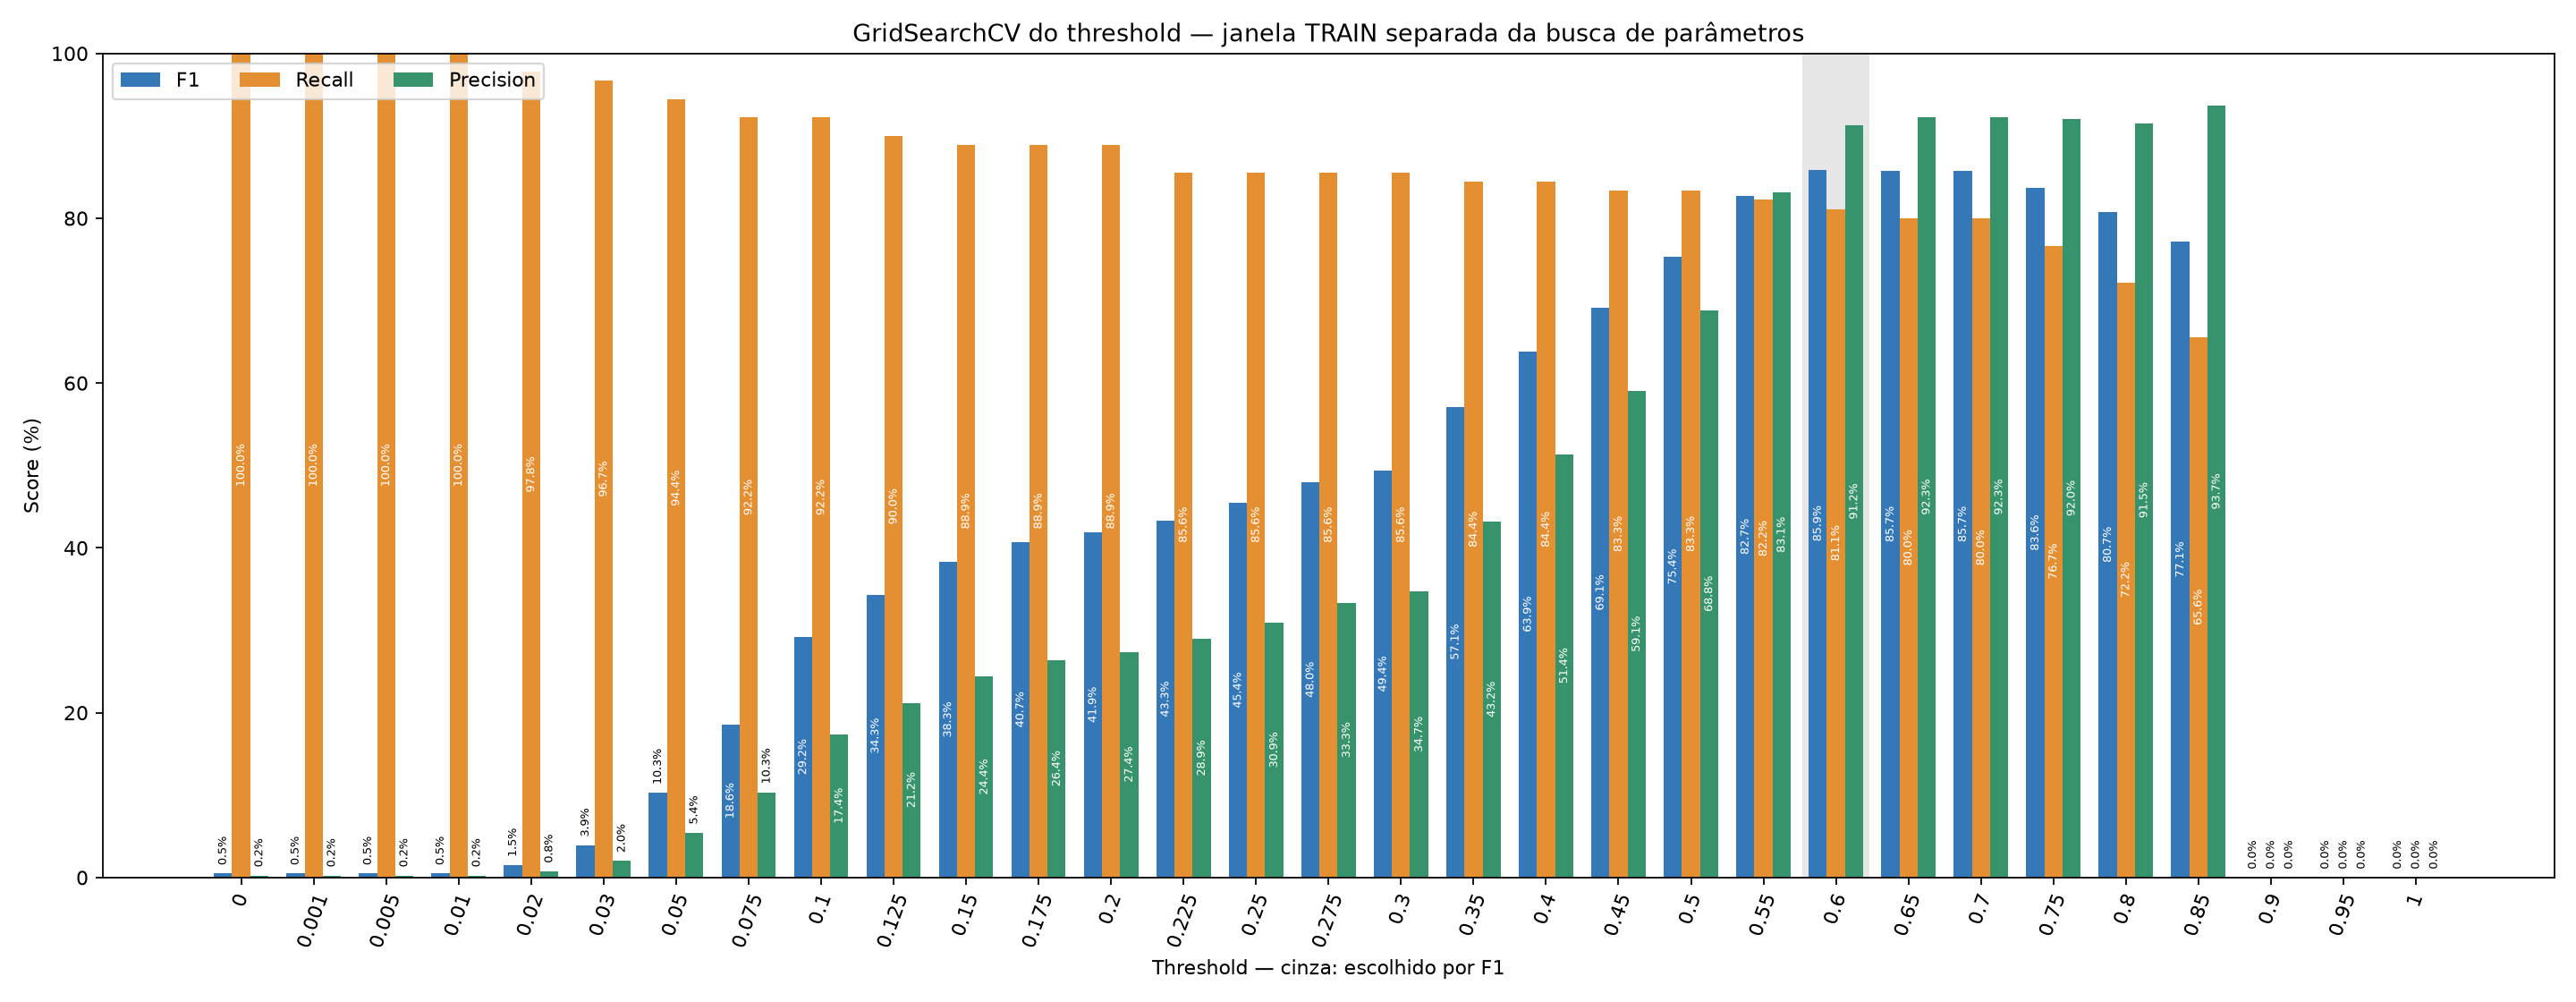

In [9]:
thresholds = table("thresholds")
show(thresholds[["threshold", "f1", "recall", "precision", "average_precision", "tp", "fp", "fn", "tn", "alerts"]])
assert thresholds.average_precision.max() - thresholds.average_precision.min() < 1e-12
figure("thresholds", 1400)

## 9. CV usada para selecionar parâmetros: F1, Recall e Precision

As barras mostram médias e desvio dos dois folds de seleção. F1 decide a escolha;
Recall e Precision explicam o equilíbrio. Os scores usam referência comum 0,50
somente na comparação dos parâmetros; o limiar final é escolhido depois.
O desvio não é intervalo de confiança, e a CV participou da seleção.

Treino e validação usam a distribuição original. Períodos e tamanho do treino
mudam entre folds, então os gráficos não são learning curves controladas.
AP é apresentada adicionalmente como diagnóstico, sem orientar a seleção.

,Fold temporal,Origem,AP (score),train_average_precision,ROC-AUC (score),F1 (%),Recall (%),Precision (%),train_f1,train_recall,train_precision
0,1,CV TRAIN anterior à janela de threshold,"0,7801","0,9341","0,9621",80.79%,74.39%,88.41%,82.40%,95.05%,72.73%
1,2,CV TRAIN anterior à janela de threshold,"0,7404","0,8379","0,9558",84.11%,76.27%,93.75%,83.59%,89.07%,78.74%


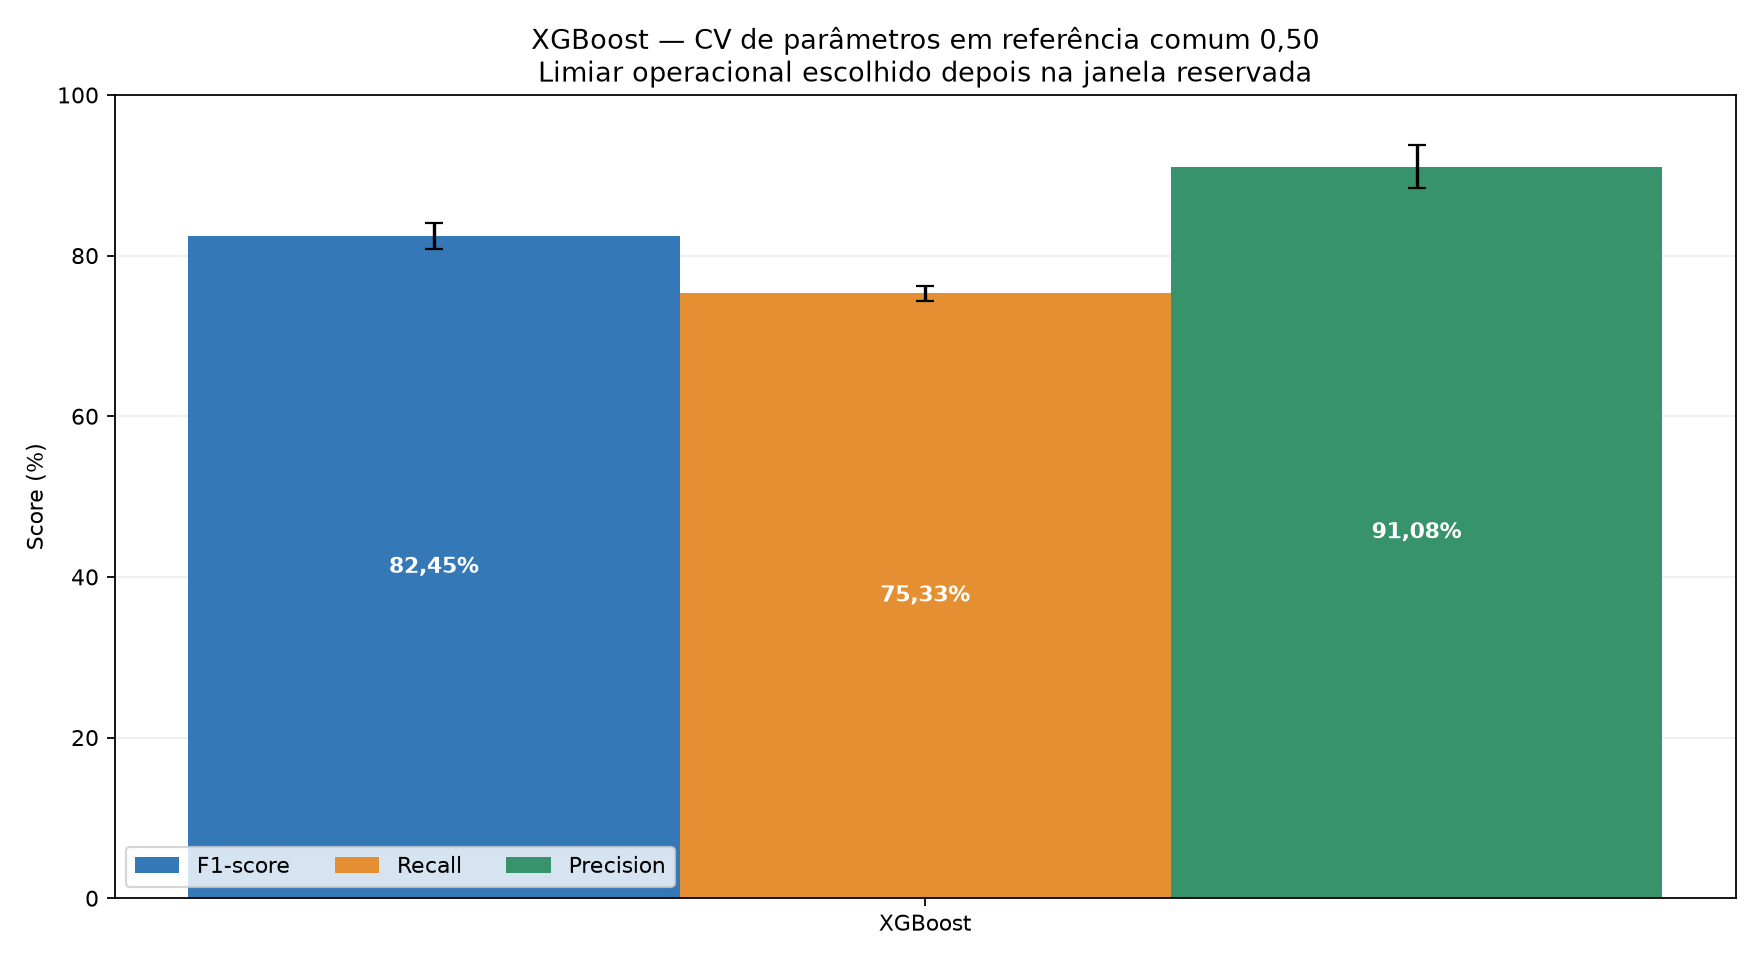

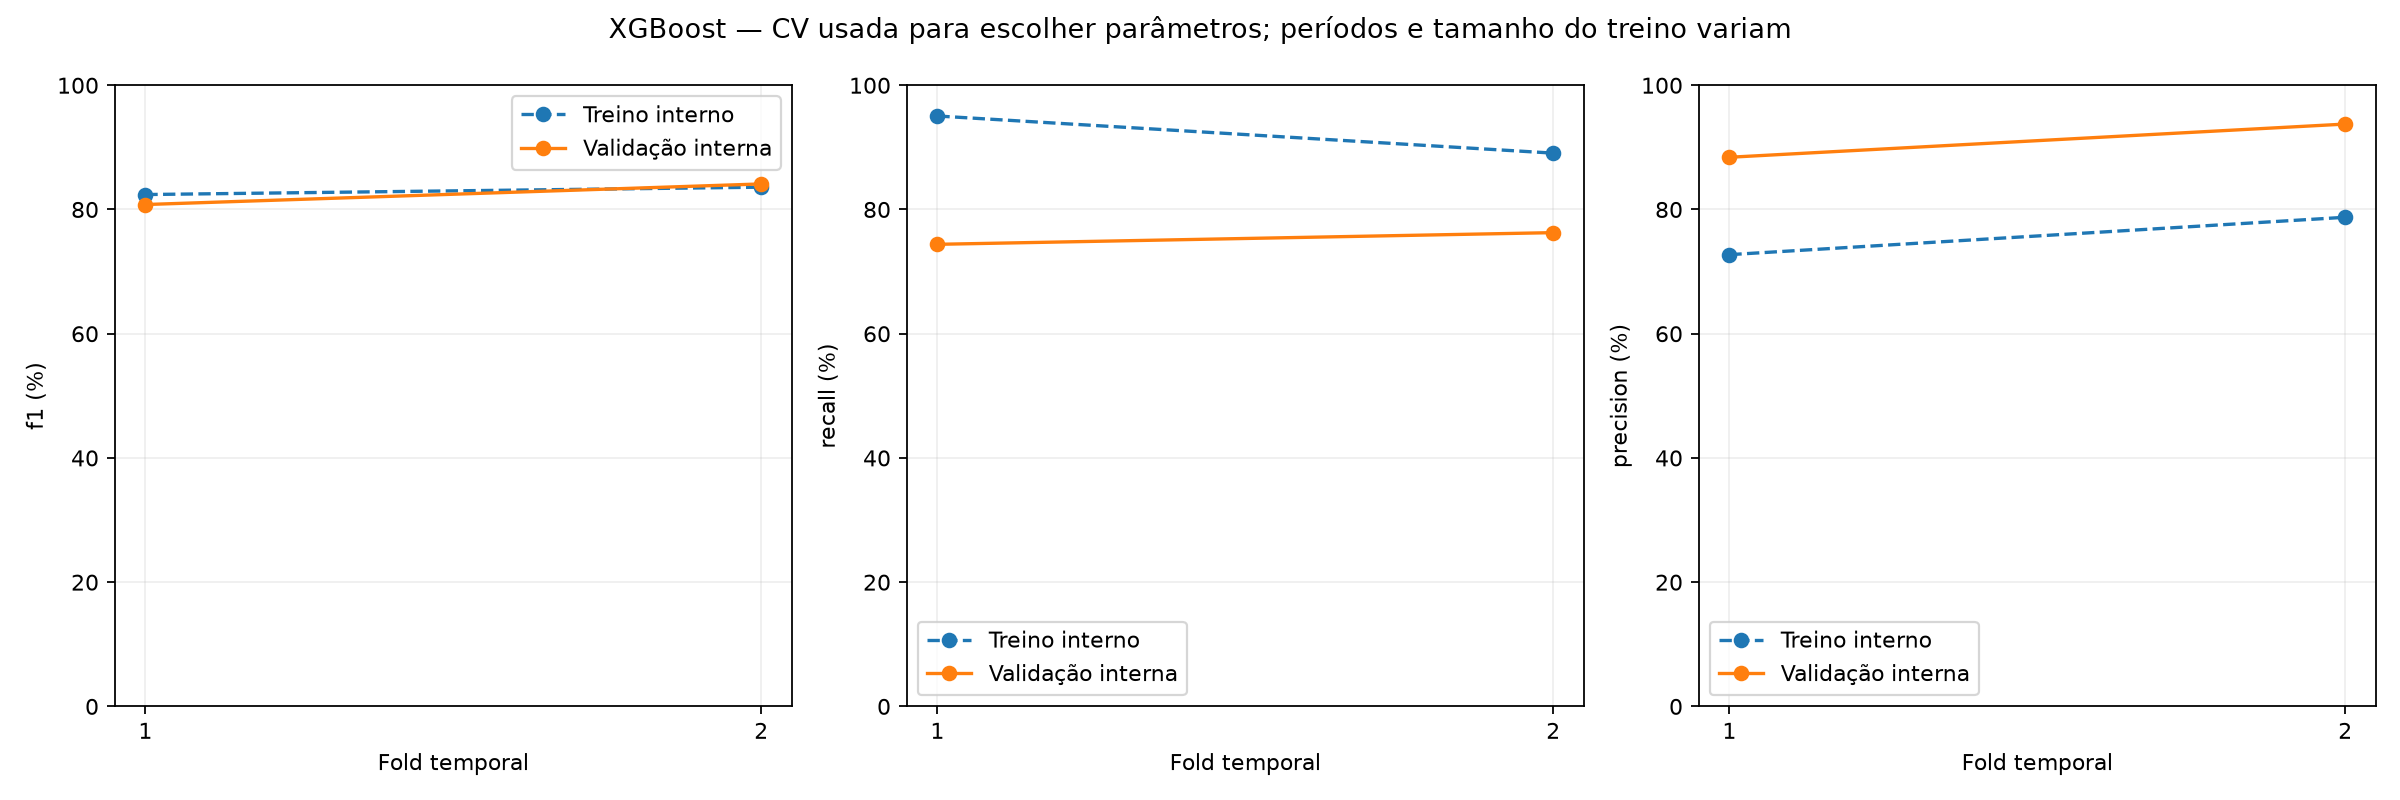

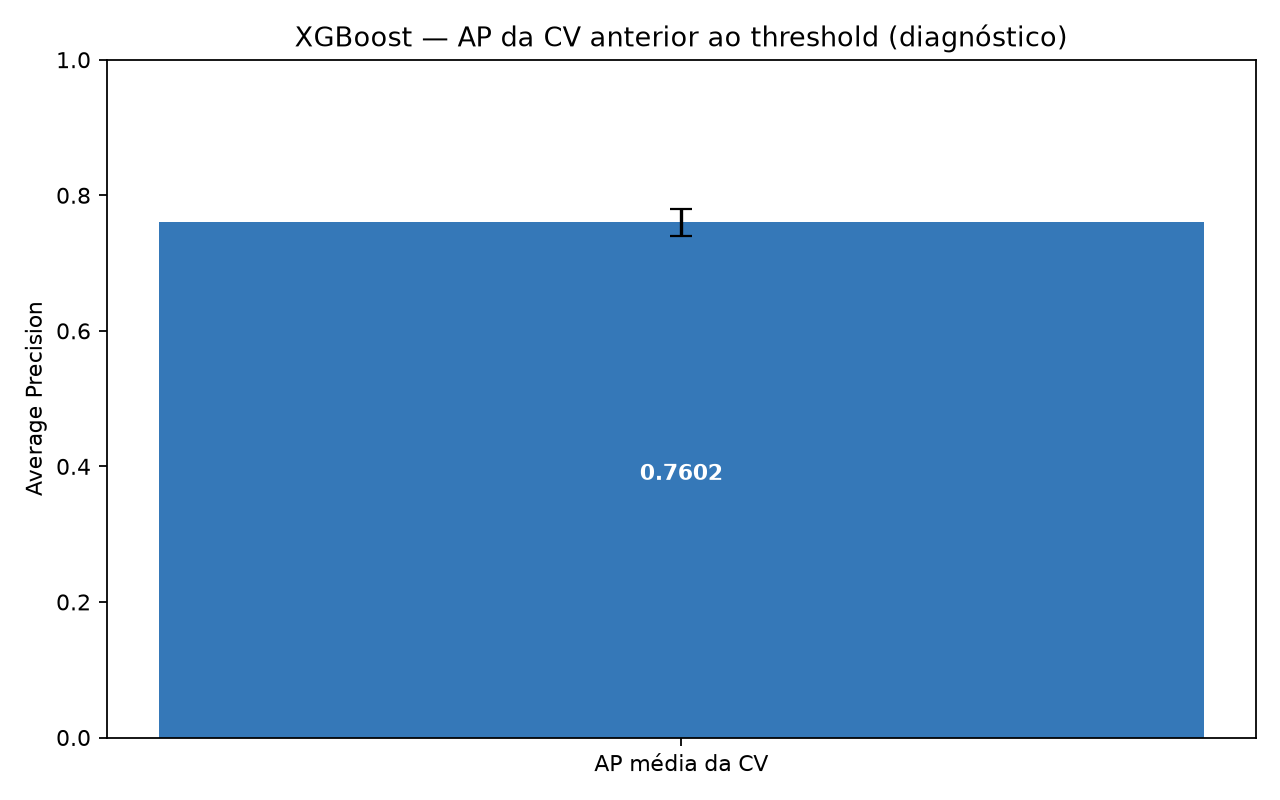

In [10]:
folds = table("fold_metrics")
show(folds)
figure("model_cv_f1_recall_precision")
figure("model_train_validation", 1300)
figure("model_cv_ap", 900)

## 10. Melhores parâmetros e learning_rate por F1

Os perfis mostram a combinação de maior F1 médio em cada valor do parâmetro.
Os demais parâmetros podem mudar; não é efeito isolado ou prova causal.
A tabela apresenta F1, Recall, Precision e AP, mantendo claro que F1 decide.
A melhor combinação vale para a grade e os folds, sem garantia de ótimo global.

,learning_rate,max_depth,n_estimators,reg_alpha,reg_lambda,mean_test_f1,std_test_f1,mean_test_recall,mean_test_precision,mean_test_average_precision
0,0.0100,4,200,0.0000,1.0000,0.8245,0.0166,0.7533,0.9108,0.7602
1,0.0500,6,400,0.0000,0.0000,0.8024,0.0079,0.7520,0.8654,0.7773
2,0.1000,4,400,1.0000,5.0000,0.8031,0.0132,0.7642,0.8532,0.7812


,rank_test_f1,learning_rate,max_depth,n_estimators,reg_alpha,reg_lambda,mean_test_f1,std_test_f1,mean_test_recall,mean_test_precision,mean_test_average_precision
0,1,0.0100,4,200,0.0000,1.0000,0.8245,0.0166,0.7533,0.9108,0.7602
1,2,0.0100,4,200,1.0000,5.0000,0.8232,0.0179,0.7472,0.9165,0.7635
2,3,0.0100,4,200,1.0000,0.0000,0.8219,0.0192,0.7411,0.9226,0.7600
3,4,0.0100,4,200,0.0000,5.0000,0.8206,0.0206,0.7472,0.9099,0.7648
4,4,0.0100,4,200,1.0000,1.0000,0.8206,0.0206,0.7472,0.9099,0.7605
5,6,0.0100,4,200,0.0000,0.0000,0.8192,0.0219,0.7411,0.9157,0.7702
6,7,0.0100,3,200,0.0000,0.0000,0.8152,0.0072,0.7448,0.9004,0.7465
7,8,0.0100,3,100,1.0000,0.0000,0.8148,0.0121,0.7242,0.9316,0.7731
8,8,0.0100,3,100,1.0000,1.0000,0.8148,0.0121,0.7242,0.9316,0.7731
9,10,0.0100,3,200,0.0000,1.0000,0.8141,0.0007,0.7448,0.8975,0.7686


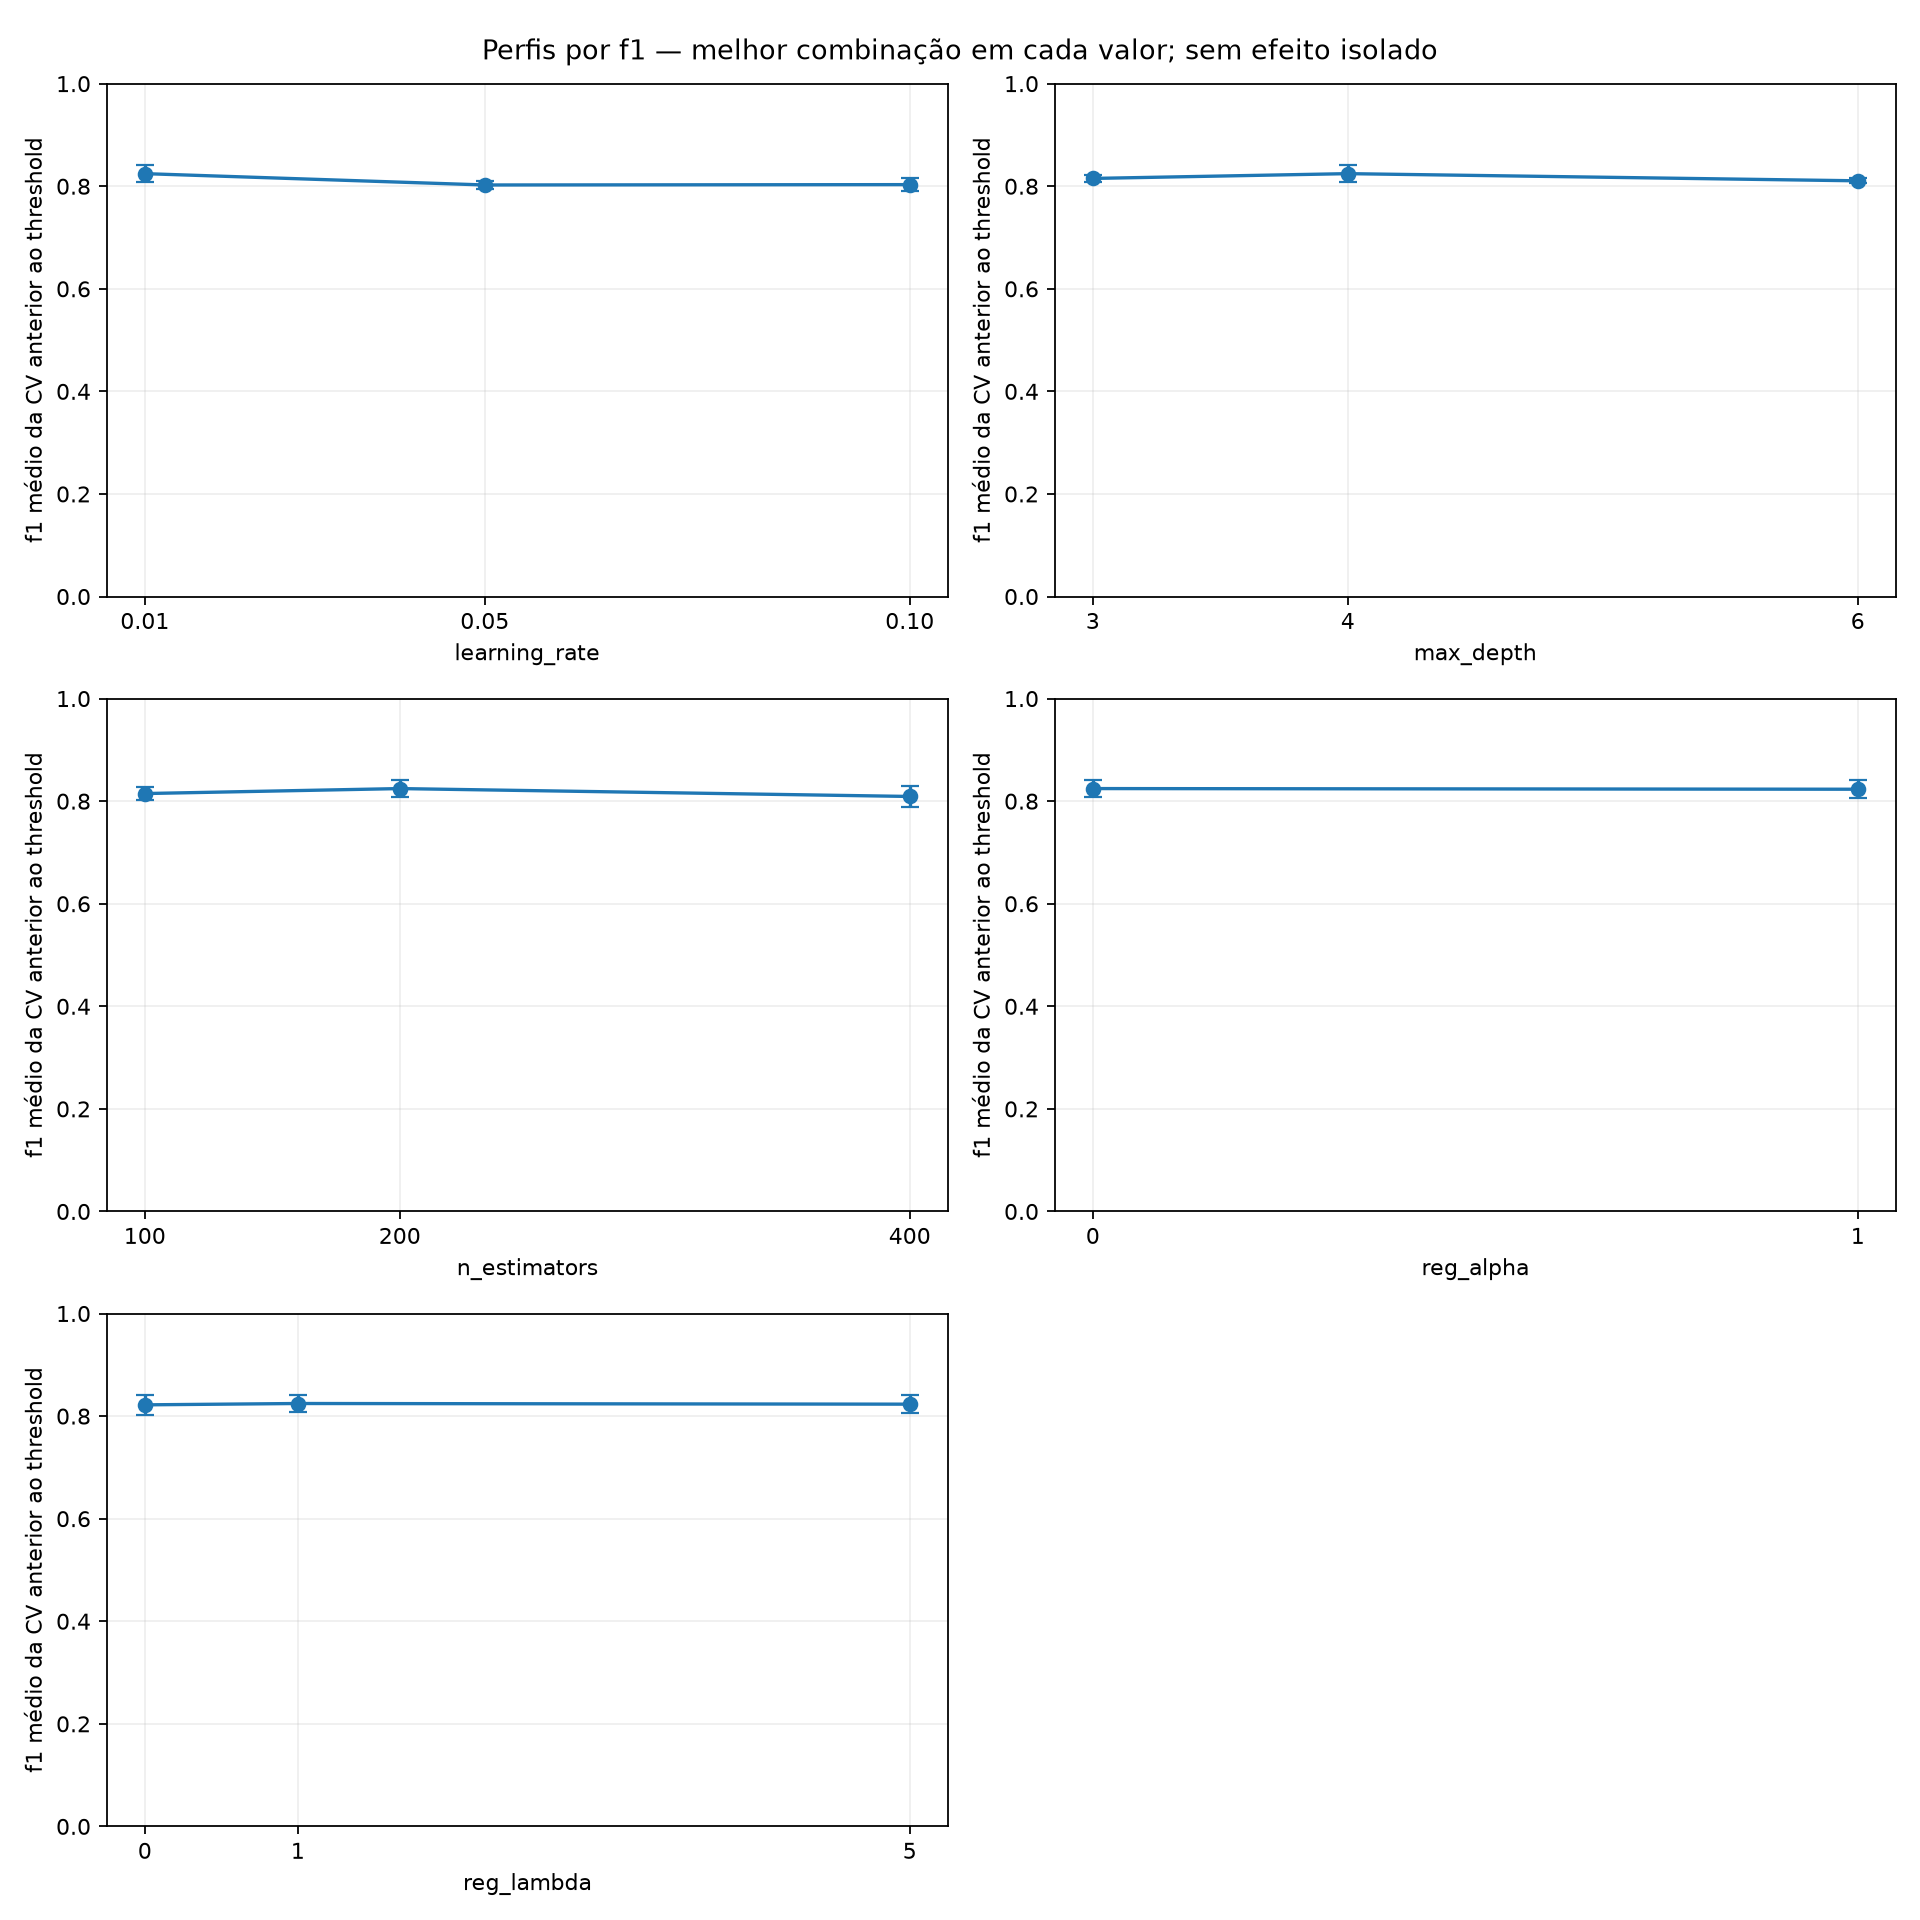

In [11]:
columns = ["param_model__learning_rate", "param_model__max_depth", "param_model__n_estimators",
           "param_model__reg_alpha", "param_model__reg_lambda", "mean_test_f1", "std_test_f1",
           "mean_test_recall", "mean_test_precision", "mean_test_average_precision"]
profiles = table("learning_rate_profiles")
display(profiles[columns].rename(columns=lambda name: name.removeprefix("param_model__")).style.format(precision=4))
grid = table("results").sort_values("rank_test_f1")
display(grid[["rank_test_f1", *columns]].head(12)
        .rename(columns=lambda name: name.removeprefix("param_model__")).style.format(precision=4))
figure("parameters")

## 11. Curvas por quantidade de árvores: F1, AP e Log Loss

Os prefixos de árvores do modelo treinado são previstos com iteration_range,
sem outro fit para cada ponto. n_estimators já foi escolhido pela CV interna;
as curvas abaixo são apenas diagnóstico posterior em treino e validação separada.
Não há escolha de outro número de árvores nem early stopping com essa validação.

Treino melhor e validação pior podem sugerir sobreajuste ou mudança temporal.
F1 pode variar de forma não monotônica conforme os scores cruzam o limiar escolhido. Log Loss
pode melhorar sem melhorar F1 ou AP, porque mede outra propriedade das previsões.

,trees,train_f1,train_average_precision,train_log_loss,validation_f1,validation_average_precision,validation_log_loss
0,25,0.00%,"0,7341","0,0794","0,0000","0,6840","0,0787"
1,50,0.00%,"0,7454","0,0642","0,0000","0,6814","0,0653"
2,100,82.23%,"0,7592","0,0435","0,7273","0,6807","0,0475"
3,200,82.70%,"0,8041","0,0237","0,6800","0,6958","0,0303"


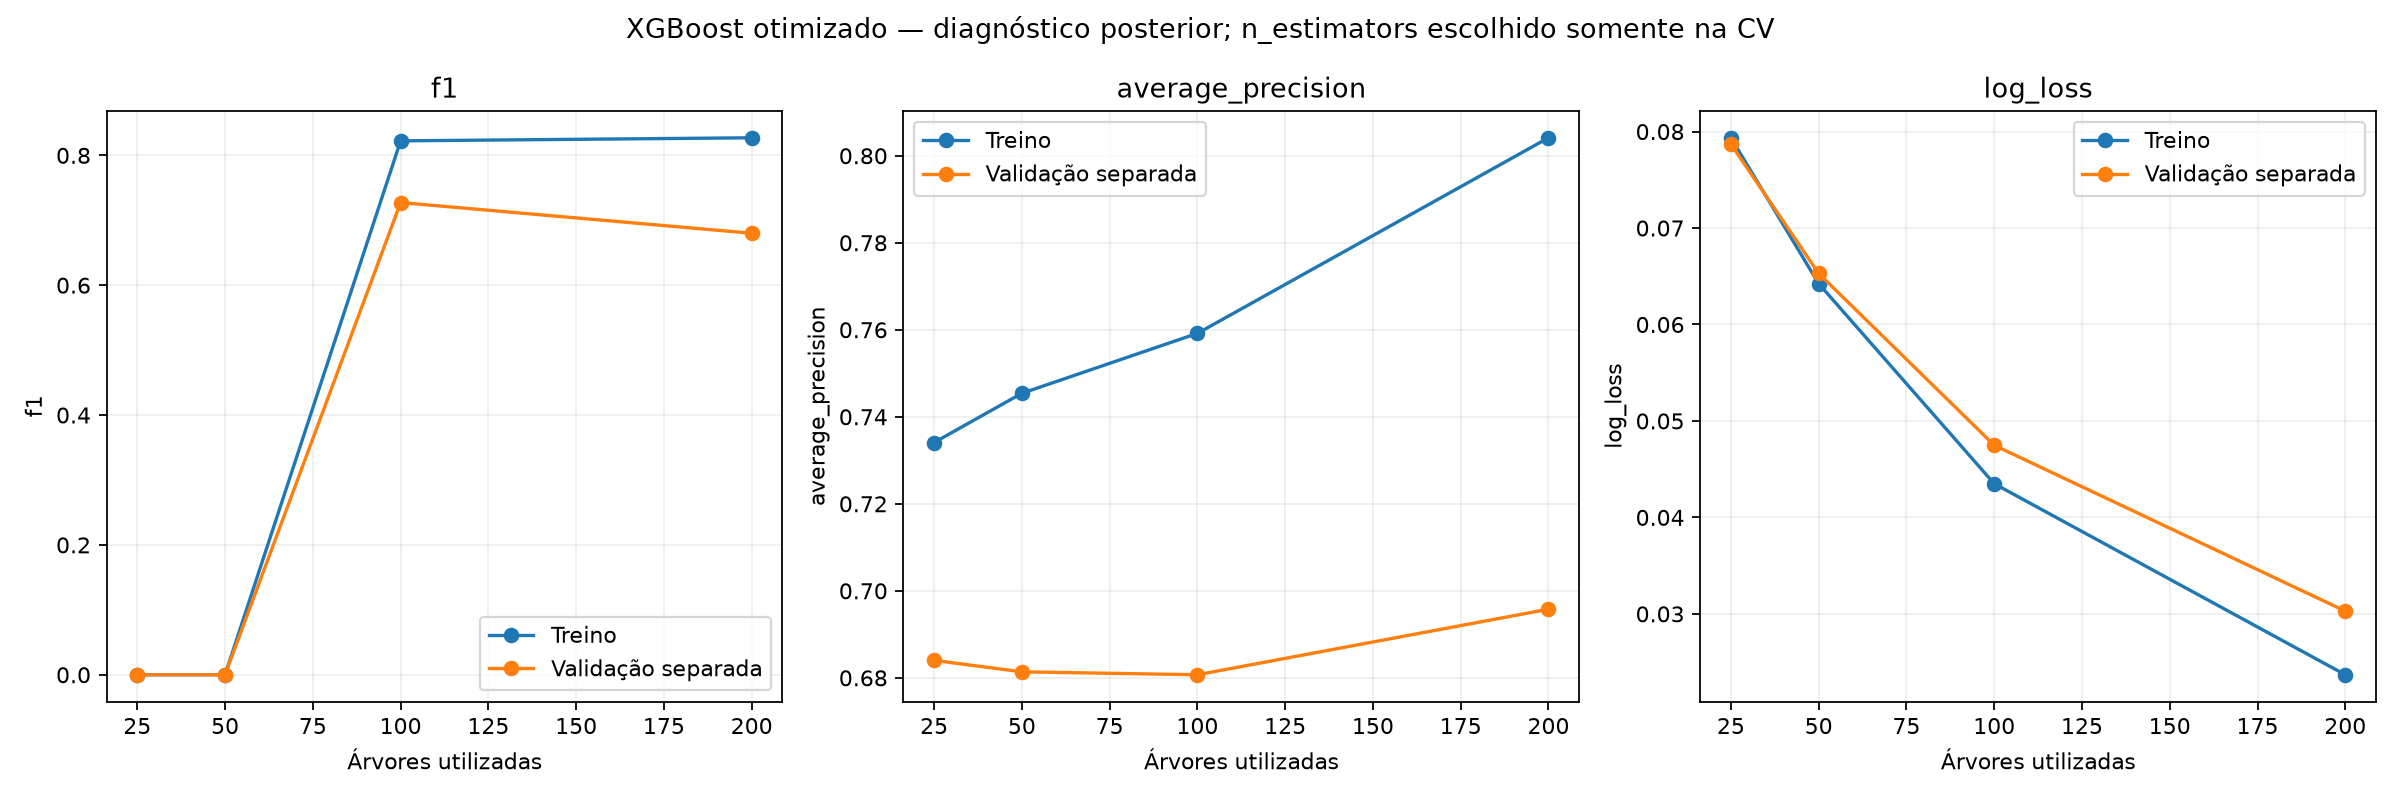

In [12]:
show(table("iterations"))
figure("iterations", 1300)

## 12. Calibração e distribuição dos scores

Log Loss penaliza previsões probabilísticas erradas, especialmente confiantes;
Brier é o erro quadrático médio entre score e rótulo. A confiabilidade por faixa
compara score médio com a fração real de fraude; a diagonal é a referência ideal.
As distribuições são normalizadas dentro de cada classe, não pela base inteira.

SMOTE altera a prevalência do treino e não houve calibração. Um score 0,50 não
foi demonstrado como 50% de chance operacional de fraude. As faixas são diagnósticas
e não reajustam probabilidades ou o threshold já escolhido.

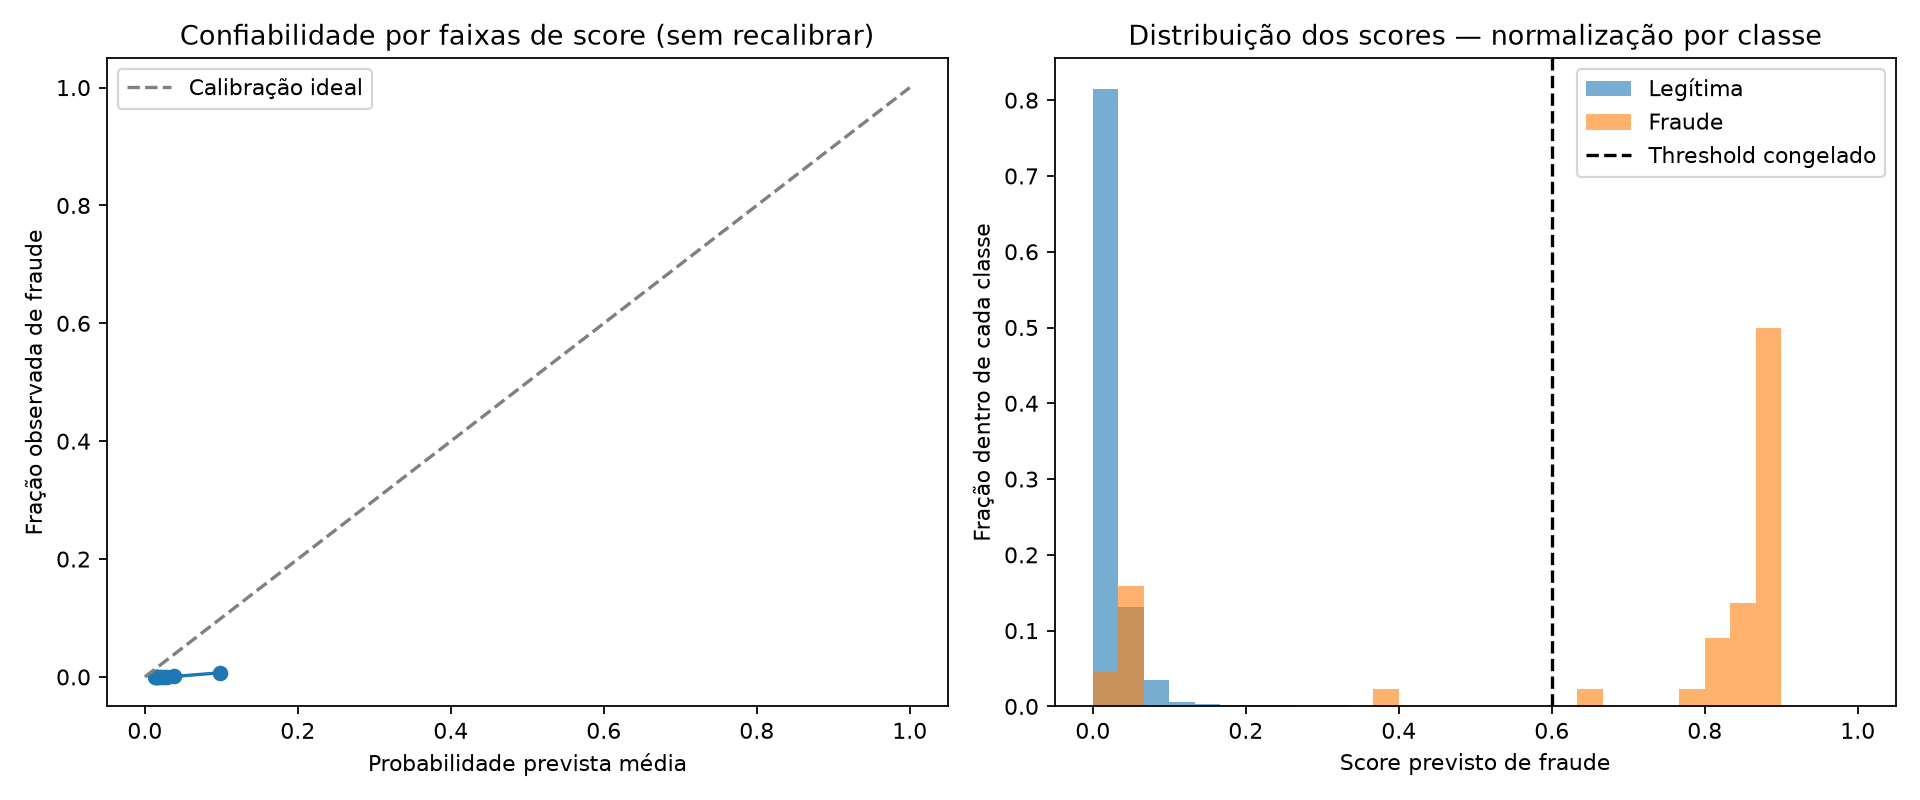

,Faixa de score,Transações,Fraudes,Score médio,Frequência de fraude,Score mínimo,Score máximo
0,"(0.012400000000000001, 0.0141]",6198,0,1.3920%,0.0000%,0.0134,0.0141
1,"(0.0141, 0.0147]",4767,0,1.4360%,0.0000%,0.0141,0.0147
2,"(0.0147, 0.0156]",5283,0,1.5163%,0.0000%,0.0147,0.0156
3,"(0.0156, 0.0175]",5425,0,1.6472%,0.0000%,0.0156,0.0175
4,"(0.0175, 0.0197]",5407,0,1.8529%,0.0000%,0.0175,0.0197
5,"(0.0197, 0.0226]",5415,0,2.1106%,0.0000%,0.0197,0.0225
6,"(0.0226, 0.0267]",5417,2,2.4508%,0.0369%,0.0226,0.0267
7,"(0.0267, 0.0322]",5416,0,2.9197%,0.0000%,0.0267,0.0322
8,"(0.0322, 0.0471]",5415,4,3.7645%,0.0739%,0.0322,0.0471
9,"(0.0471, 0.875]",5416,38,9.8117%,0.7016%,0.0471,0.8746


In [13]:
figure("calibration_scores")
calibration = table("calibration").rename(columns={
    "score_bin": "Faixa de score", "count": "Transações", "fraud_count": "Fraudes",
    "predicted_probability": "Score médio", "observed_fraud_rate": "Frequência de fraude",
    "min_probability": "Score mínimo", "max_probability": "Score máximo",
})
display(calibration.style.format({"Score médio": "{:.4%}", "Frequência de fraude": "{:.4%}",
                                  "Score mínimo": "{:.4f}", "Score máximo": "{:.4f}"}))

## 13. Correlação, seleção e importância das features

A seleção da tabela foi reaprendida no prefixo de busca para o refit. Cada fold
teve sua própria seleção, aprendida somente no treino correspondente.
Pearson/Spearman usam o prefixo TRAIN; importância por permutação mede queda de AP
na validação separada, depois de congelar parâmetros. Não altera o modelo.

Os painéis têm escalas diferentes. Correlação e importância não implicam causalidade.
A importância interna das árvores também tem vieses e pode dividir crédito entre
features correlacionadas. Colunas retiradas recebem importância zero no pipeline
porque não são usadas, não como prova universal de irrelevância.

,Feature,Pearson com Class,Queda de AP por permutação,Manter?,Remover?,reference_fit_time_max,reference_validation_time_min,selection_input_time_max
0,Time,"-0,0188","0,0000",False,True,"60.647,0000","60.648,0000","75.810,0000"
1,V1,"-0,1344","0,0002",True,False,"60.647,0000","60.648,0000","75.810,0000"
2,V2,"0,1081","0,0010",True,False,"60.647,0000","60.648,0000","75.810,0000"
3,V3,"-0,2827","-0,0011",True,False,"60.647,0000","60.648,0000","75.810,0000"
4,V4,"0,1523","0,0665",True,False,"60.647,0000","60.648,0000","75.810,0000"
5,V5,"-0,1311","0,0024",True,False,"60.647,0000","60.648,0000","75.810,0000"
6,V6,"-0,0607","-0,0179",False,True,"60.647,0000","60.648,0000","75.810,0000"
7,V7,"-0,2218","0,0003",True,False,"60.647,0000","60.648,0000","75.810,0000"
8,V8,"0,0865","0,0065",False,True,"60.647,0000","60.648,0000","75.810,0000"
9,V9,"-0,1096","0,0024",True,False,"60.647,0000","60.648,0000","75.810,0000"


,Feature,Usada no último fold?,Pearson com Class,Spearman com Class,Queda de AP por permutação,Desvio da permutação,Importância interna da árvore
0,Time,False,"-0,0188","-0,0184","0,0000","0,0000","0,0000"
1,V1,True,"-0,1344","-0,0483","-0,0104","0,0173","0,0121"
2,V2,True,"0,1081","0,0571","-0,0006","0,0001","0,0092"
3,V3,True,"-0,2827","-0,0671","-0,0011","0,0175","0,0174"
4,V4,True,"0,1523","0,0682","0,0623","0,0251","0,0293"
5,V5,True,"-0,1311","-0,0394","-0,0061","0,0153","0,0222"
6,V6,False,"-0,0607","-0,0480","0,0000","0,0000","0,0000"
7,V7,True,"-0,2218","-0,0536","0,0083","0,0192","0,0096"
8,V8,False,"0,0865","0,0313","0,0000","0,0000","0,0000"
9,V9,True,"-0,1096","-0,0538","-0,0131","0,0042","0,0104"


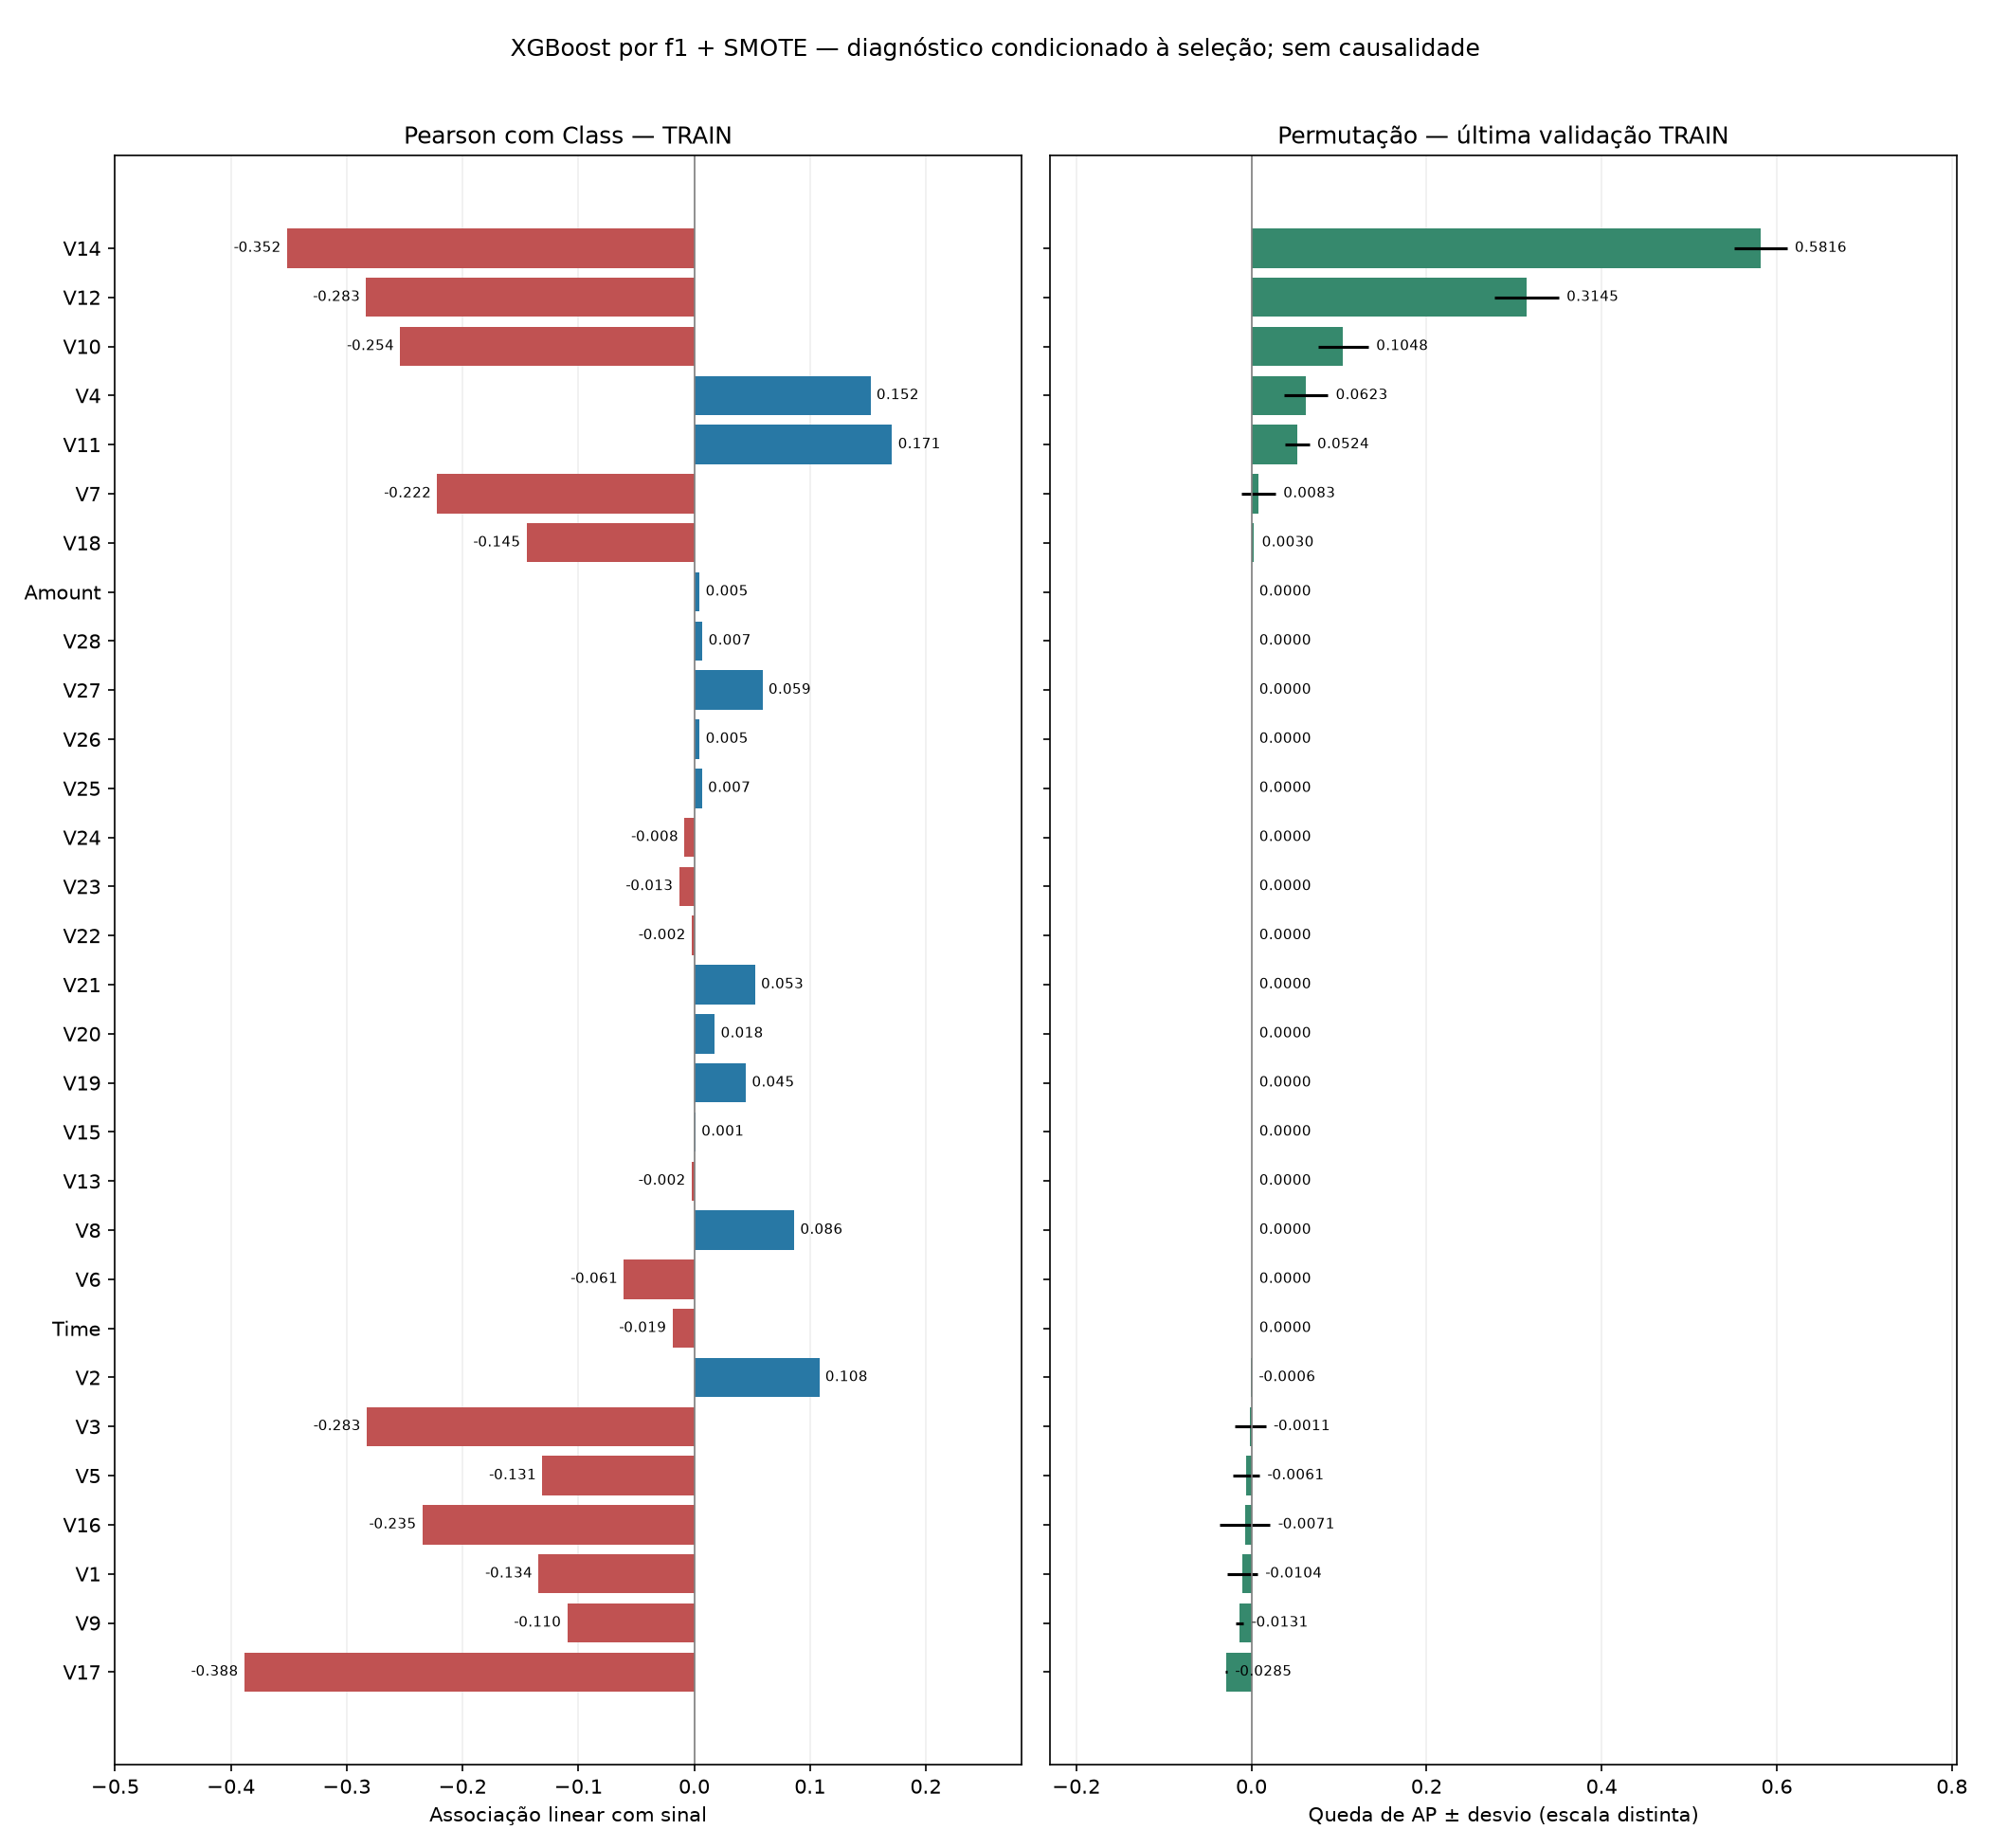

In [14]:
show(table("feature_selection")[["feature", "pearson", "permutation_ap", "keep", "remove",
                                "reference_fit_time_max", "reference_validation_time_min", "selection_input_time_max"]])
show(table("association_importance")[["feature", "selected_last_fold", "pearson", "spearman",
                                     "permutation_ap", "permutation_std", "tree_importance"]])
figure("association_importance")

## 14. Fraudes e erros por faixa de feature

As faixas são aprendidas no prefixo TRAIN e aplicadas à validação separada, em
threshold selecionado na janela interna. Não são categorias semânticas ou modalidades reais de fraude.

- Fraude na faixa (%): fraudes reais / transações da faixa.
- Recall da faixa (%): TP/(TP+FN).
- Precision da faixa (%): TP/(TP+FP).
- FPR da faixa (%): FP/(FP+TN), legítimas que receberam alerta.
- Alertas falsos (%): FP/(FP+TP), parcela de alertas que era legítima.

Leia taxas junto às contagens; poucos eventos geram estimativas instáveis.
“Não definido” indica denominador zero. Não some features distintas, pois as
mesmas transações reaparecem em cada feature. Estes recortes não geram novo tuning.

In [15]:
# Muda somente a apresentação; todas as features já estão no CSV persistido.
FEATURE_TO_INSPECT = "V10"
errors = table("category_errors")
show(errors.loc[errors.feature.eq(FEATURE_TO_INSPECT), [
    "feature", "bin", "count", "fraud_count", "legitimate_count", "tp", "fp", "fn", "tn",
    "fraud_rate_pct", "recall_pct", "precision_pct", "false_positive_rate_pct",
    "missed_fraud_rate_pct", "false_alert_share_pct", "alert_rate_pct",
]])

,Feature,Faixa de valores,Quantidade,Fraudes confirmadas,Transações legítimas,TP: fraudes detectadas,FP: falsos alertas,FN: fraudes não detectadas,TN: legítimas liberadas,Fraude na faixa (%),Recall da faixa (%),Precision da faixa (%),Falsos positivos entre legítimas (%),Fraudes não detectadas (%),Alertas que eram falsos (%),Taxa de alertas da faixa (%)
91,V10,"(-0.961, -0.587]",6.225,0,6.225,0,0,0,6.225,0.0000%,Não definido,Não definido,0.00%,Não definido,Não definido,0.00%
92,V10,"(-inf, -0.961]",6.192,36,6.156,32,21,4,6.135,0.5814%,88.89%,60.38%,0.34%,11.1111%,39.62%,0.86%
93,V10,"(0.919, inf]",9.284,3,9.281,0,0,3,9.281,0.0323%,0.00%,Não definido,0.00%,100.0000%,Não definido,0.00%
94,V10,"(0.594, 0.919]",4.394,0,4.394,0,0,0,4.394,0.0000%,Não definido,Não definido,0.00%,Não definido,Não definido,0.00%
95,V10,"(-0.587, -0.379]",4.899,0,4.899,0,0,0,4.899,0.0000%,Não definido,Não definido,0.00%,Não definido,Não definido,0.00%
96,V10,"(-0.228, -0.0929]",3.758,0,3.758,0,0,0,3.758,0.0000%,Não definido,Não definido,0.00%,Não definido,Não definido,0.00%
97,V10,"(0.0345, 0.247]",6.637,2,6.635,0,0,2,6.635,0.0301%,0.00%,Não definido,0.00%,100.0000%,Não definido,0.00%
98,V10,"(-0.379, -0.228]",3.773,0,3.773,0,1,0,3.772,0.0000%,Não definido,0.00%,0.03%,Não definido,100.00%,0.03%
99,V10,"(0.247, 0.594]",5.326,2,5.324,2,0,0,5.324,0.0376%,100.00%,100.00%,0.00%,0.0000%,0.00%,0.04%
100,V10,"(-0.0929, 0.0345]",3.671,1,3.670,0,0,1,3.670,0.0272%,0.00%,Não definido,0.00%,100.0000%,Não definido,0.00%


## 15. Conclusão e limites — TEST separado

F1 escolheu os parâmetros na CV e o threshold na janela reservada. Recall e
Precision acompanham as decisões; AP/AUPRC é diagnóstico. A validação posterior
ficou fora das duas escolhas nesta rodada, mas o histórico já explorou esses dados.
Não é confirmação independente de todo o projeto.

Não houve refit após threshold, calibração, nova avaliação de TEST ou substituição
automática do RF escolhido. Para confirmar generalização após as iterações,
é necessário outro período de dados ainda não consultado.

In [16]:
display(Markdown(
    f"**Parâmetros por F1:** `{manifest['best_params']}`. "
    f"**F1 médio na CV:** {manifest['best_cv_score']:.2%}. "
    f"**Threshold escolhido por F1:** {manifest['threshold']:.4f}. "
    f"Na validação posterior: **F1 {result['f1']:.2%}**, **Recall {result['recall']:.2%}**, "
    f"**Precision {result['precision']:.2%}**, **AP {result['average_precision']:.4f}**."
))
display(manifest["limitations"])

**Parâmetros por F1:** `{'learning_rate': 0.01, 'max_depth': 4, 'n_estimators': 200, 'reg_alpha': 0.0, 'reg_lambda': 1.0}`. **F1 médio na CV:** 82.45%. **Threshold escolhido por F1:** 0.6000. Na validação posterior: **F1 68.00%**, **Recall 77.27%**, **Precision 60.71%**, **AP 0.6958**.

['F1 equilibra Precision e Recall; AP permanece diagnóstico quando F1 é a métrica de seleção.',
 'Seleção usa somente os folds anteriores à janela de threshold; limiar final é ajustado por F1 nessa janela.',
 'Na CV de parâmetros, F1/Recall/Precision usam a referência comum 0,50; o limiar operacional não fica fixado nesse valor.',
 'Validação TRAIN ficou fora de ambas as escolhas nesta rodada, mas o histórico já explorou esses dados.',
 'O mesmo pipeline congelado usado no threshold é aplicado à validação, sem refit posterior ou calibração.',
 'Não houve novo TEST; confirmação independente exige dados novos.']